# CLIP Baseline: Dataset Preparation and Image Embedding

## Purpose of this notebook

This notebook establishes the **reproducible CLIP image-embedding baseline** for the architectural retrieval study. Its job: verify the dataset, construct image-level metadata, load the pretrained CLIP vision encoder, generate one normalized embedding per image, and save those embeddings for downstream retrieval evaluation.

The notebook proceeds in five stages:

1. **Discover and inspect the dataset.** Confirm the dataset path, image count, style folders, and per-style counts.
2. **Create metadata.** Assign a stable image ID and record each image path and dataset style label.
3. **Perform basic data-quality checks.** Check duplicates/missing values and visually inspect a sample of images.
4. **Load and validate CLIP.** Confirm the PyTorch/CUDA environment and load `openai/clip-vit-base-patch32`.
5. **Generate and save normalized image embeddings.** First test the pipeline on one image, then encode the full dataset in batches and verify the saved embedding file.

The saved metadata and embedding matrix become the inputs to the later retrieval-evaluation notebooks.


In [1]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

DATASET_ROOT = Path(
    "/mnt/c/Users/theom/architecture-data/architectural-styles-dataset"
)

print("Dataset exists:", DATASET_ROOT.exists())
print("Dataset root:", DATASET_ROOT)

# Find image files recursively
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

image_paths = [
    p for p in DATASET_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print("\nNumber of images:", len(image_paths))

Dataset exists: True
Dataset root: /mnt/c/Users/theom/architecture-data/architectural-styles-dataset

Number of images: 10113


## 1. Inspect the dataset directory structure

The dataset is organized by folders, with each image's **parent folder name used as its architectural-style label**. Before constructing metadata, we inspect the top-level directory to confirm that the expected style folders are present and that the path points to the intended dataset.

This is a simple but important reproducibility check: if the dataset root or folder structure changes, all downstream style labels would be affected.


In [2]:
top_level = sorted(DATASET_ROOT.iterdir())

print("Top-level contents:")
for item in top_level:
    print(item.name)

Top-level contents:
Achaemenid architecture
American Foursquare architecture
American craftsman style
Ancient Egyptian architecture
Art Deco architecture
Art Nouveau architecture
Baroque architecture
Bauhaus architecture
Beaux-Arts architecture
Byzantine architecture
Chicago school architecture
Colonial architecture
Deconstructivism
Edwardian architecture
Georgian architecture
Gothic architecture
Greek Revival architecture
International style
Novelty architecture
Palladian architecture
Postmodern architecture
Queen Anne architecture
Romanesque architecture
Russian Revival architecture
Tudor Revival architecture


## 2. Count images by architectural style

Here we derive the dataset's style distribution directly from the folder structure. For every discovered image, the parent directory supplies the nominal architectural-style label.

The resulting counts serve two purposes. First, they verify that all expected style categories are represented. Second, they document **class imbalance**: architectural styles need not contain equal numbers of images. That imbalance matters later when retrieval results are evaluated and when frequency-aware null baselines are constructed.

At this stage these labels are treated as the dataset's categorical ground truth; they are not yet being interpreted as a complete measure of architectural relevance.


In [3]:
from collections import Counter

style_counts = Counter()

for path in image_paths:
    style = path.parent.name
    style_counts[style] += 1

print("Number of styles:", len(style_counts))
print()

for style, count in sorted(style_counts.items()):
    print(f"{style:35s} {count:4d}")

Number of styles: 25

Achaemenid architecture              392
American Foursquare architecture     362
American craftsman style             364
Ancient Egyptian architecture        406
Art Deco architecture                566
Art Nouveau architecture             615
Baroque architecture                 456
Bauhaus architecture                 315
Beaux-Arts architecture              424
Byzantine architecture               313
Chicago school architecture          278
Colonial architecture                480
Deconstructivism                     335
Edwardian architecture               280
Georgian architecture                381
Gothic architecture                  331
Greek Revival architecture           523
International style                  417
Novelty architecture                 382
Palladian architecture               343
Postmodern architecture              322
Queen Anne architecture              720
Romanesque architecture              301
Russian Revival architecture       

## 3. Construct image-level metadata

We now create one metadata record per image. Each record contains:

- `image_id`: a deterministic integer identifier assigned after sorting the image paths;
- `image_path`: the full path used to load the image;
- `style`: the architectural-style label inherited from the image's parent folder.

Sorting the paths before assigning IDs makes the mapping reproducible: rerunning the notebook on the same directory structure should assign the same image IDs in the same order. This matters because the row order of the embedding matrix generated later must correspond exactly to the row order of this metadata table.


In [4]:

import pandas as pd

records = []

for image_id, path in enumerate(sorted(image_paths)):
    records.append({
        "image_id": image_id,
        "image_path": str(path),
        "style": path.parent.name
    })

metadata = pd.DataFrame(records)

print(metadata.shape)
metadata.head(10)

(10113, 3)


,image_id,image_path,style
0,0,/mnt/c/Users/theom/architecture-data/architect...,Achaemenid architecture
1,1,/mnt/c/Users/theom/architecture-data/architect...,Achaemenid architecture
2,2,/mnt/c/Users/theom/architecture-data/architect...,Achaemenid architecture
3,3,/mnt/c/Users/theom/architecture-data/architect...,Achaemenid architecture
4,4,/mnt/c/Users/theom/architecture-data/architect...,Achaemenid architecture
5,5,/mnt/c/Users/theom/architecture-data/architect...,Achaemenid architecture
6,6,/mnt/c/Users/theom/architecture-data/architect...,Achaemenid architecture
7,7,/mnt/c/Users/theom/architecture-data/architect...,Achaemenid architecture
8,8,/mnt/c/Users/theom/architecture-data/architect...,Achaemenid architecture
9,9,/mnt/c/Users/theom/architecture-data/architect...,Achaemenid architecture


## 4. Basic metadata integrity checks

Before any model inference, we verify that the metadata table is internally consistent. The checks below report the total number of images and unique styles, detect duplicate image paths, and identify missing values.

These checks protect the later retrieval analysis from avoidable indexing problems. In particular, duplicate paths could cause the same physical file to appear more than once, while missing paths or labels would break the correspondence between an embedding and its architectural-style metadata.


In [5]:
print("Images:", len(metadata))
print("Styles:", metadata["style"].nunique())
print("Duplicate paths:", metadata["image_path"].duplicated().sum())

print("\nMissing values:")
print(metadata.isna().sum())

Images: 10113
Styles: 25
Duplicate paths: 0

Missing values:
image_id      0
image_path    0
style         0
dtype: int64


## 5. Visual sanity check of the dataset

Numerical checks cannot reveal every data problem, so we also inspect a small reproducible sample of images. One image is sampled from each style group using a fixed random seed, and the first eight sampled styles are displayed.

The purpose is **not** to evaluate CLIP or architectural similarity. It is simply to verify that the files open correctly, contain architectural imagery, and appear broadly consistent with their folder labels. The fixed `random_state=42` makes the displayed sample reproducible across runs.


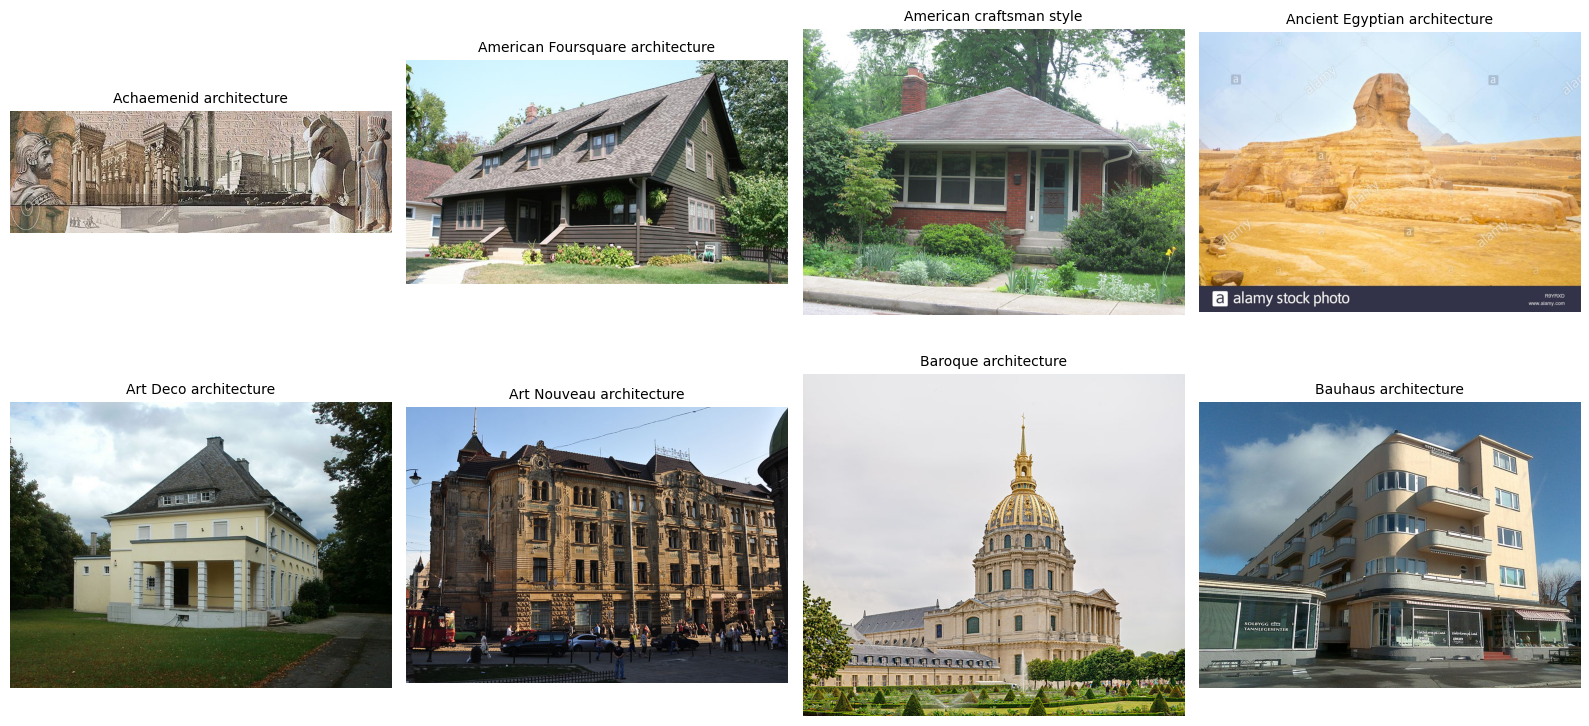

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

# Pick one random image from 8 architectural styles
sample = (
    metadata.groupby("style", group_keys=False)
    .sample(n=1, random_state=42)
    .head(8)
)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(row["style"], fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Save the metadata table

The metadata table is saved before embedding generation so that later notebooks can reload the exact image-ID/path/style mapping without reconstructing it.

This file is a companion to the embedding matrix saved later. Row `i` of the embedding matrix must correspond to row `i` of this metadata table. Preserving that alignment is essential for retrieving an image's path and style label after nearest-neighbor search.


In [7]:
metadata.to_csv("architecture_metadata.csv", index=False)

print("Saved architecture_metadata.csv")

Saved architecture_metadata.csv


## 7. Verify the PyTorch and GPU environment

CLIP inference is substantially faster on a CUDA-capable GPU. This cell records the PyTorch version, checks whether CUDA is available, and reports the GPU model when available.

These environment details are useful for reproducibility and troubleshooting. The code that follows will automatically use CUDA when available and otherwise fall back to the CPU.


In [8]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.0+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 3080 Ti Laptop GPU


## 8. Record the Transformers version

The pretrained CLIP model and processor are loaded through the Hugging Face `transformers` library. Recording its version helps document the software environment used to generate the embeddings, since library behavior and model interfaces can change between releases.


In [9]:
import transformers

print("Transformers version:", transformers.__version__)

/home/tmitsa/miniconda3/envs/architecture/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformers version: 5.17.0


## 9. Load the pretrained CLIP vision model

We use **CLIP ViT-B/32** (`openai/clip-vit-base-patch32`) as the baseline visual representation. The `CLIPProcessor` performs the image preprocessing expected by the pretrained model, while `CLIPModel` supplies the vision encoder and projection layer.

The model is moved to the selected device and placed in evaluation mode. No fine-tuning occurs in this notebook: the embeddings therefore represent the behavior of the pretrained CLIP model rather than a model adapted using our architectural labels or architectural similarity measure. 


In [10]:
import torch
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"

model_name = "openai/clip-vit-base-patch32"

processor = CLIPProcessor.from_pretrained(model_name)
model = CLIPModel.from_pretrained(model_name).to(device)

model.eval()

print("CLIP loaded")
print("Device:", device)

Loading weights: 100%|████████████████████████████████████████████████████████████| 398/398 [00:00<00:00, 12519.00it/s]


CLIP loaded
Device: cuda


## 10. Test the pipeline on one image before batch processing

Before encoding thousands of images, we load and display a single metadata record. This verifies the complete chain from metadata row → image path → readable RGB image.

Testing one example first makes failures easier to diagnose and confirms that the image being passed to CLIP corresponds to the expected image ID and style label.


Image ID: 0
Style: Achaemenid architecture
Image size: (1000, 442)


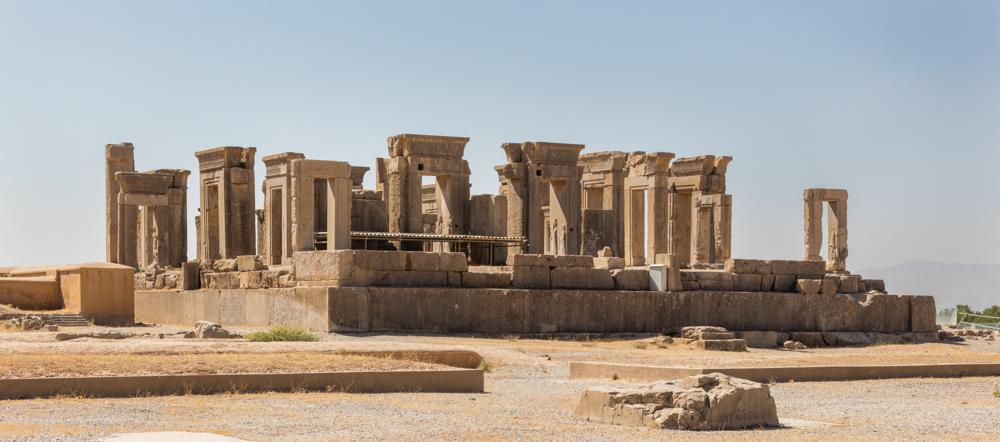

In [11]:
row = metadata.iloc[0]

image = Image.open(row["image_path"]).convert("RGB")

print("Image ID:", row["image_id"])
print("Style:", row["style"])
print("Image size:", image.size)

display(image)

## 11. Encode one image with CLIP

This cell validates the actual embedding computation before scaling it to the full dataset. The processor converts the image into CLIP-compatible pixel values. The vision transformer produces a pooled visual representation, and CLIP's learned visual projection maps that representation into the model's shared image/text embedding space.

Finally, the vector is **L2-normalized**. After normalization, the dot product between two image embeddings is equivalent to their cosine similarity. This is useful for nearest-neighbor retrieval because similarity can later be computed efficiently with matrix multiplication.

The printed shape verifies the dimensionality of the resulting image representation, while the first few values provide a basic numerical sanity check.


In [12]:
inputs = processor(images=image, return_tensors="pt")
pixel_values = inputs["pixel_values"].to(device)

with torch.no_grad():
    outputs = model.vision_model(pixel_values=pixel_values)

    # Pooled representation from the CLIP vision encoder
    pooled_output = outputs.pooler_output

    # Project into CLIP's shared image/text embedding space
    image_features = model.visual_projection(pooled_output)

# Normalize
image_embedding = image_features / image_features.norm(dim=-1, keepdim=True)

print("Embedding shape:", image_embedding.shape)
print("First 10 values:")
print(image_embedding[0, :10])

Embedding shape: torch.Size([1, 512])
First 10 values:
tensor([-0.0672,  0.0231, -0.0305, -0.0137, -0.0220,  0.0320,  0.0142,  0.0287,
         0.0131,  0.0101], device='cuda:0')


## 12. Verify embedding normalization

A correctly L2-normalized embedding should have Euclidean norm approximately equal to 1. This small check confirms that normalization was applied as intended.

This matters downstream because the retrieval evaluation interprets embedding dot products as cosine similarities. Without unit normalization, vector magnitude would influence those scores.


In [13]:
print("Norm:", image_embedding.norm().item())

Norm: 1.0


## 13. Generate CLIP embeddings for the complete dataset

After validating the single-image pipeline, we encode every image in batches. Batching improves computational efficiency and limits GPU memory usage.

For each batch, the procedure is identical to the single-image test:

1. Load the images and convert them to RGB.
2. Apply CLIP's standard image preprocessing.
3. Run the images through the pretrained vision encoder.
4. Project the pooled vision representations into CLIP's shared embedding space.
5. L2-normalize every embedding.
6. Move the results back to CPU memory and accumulate them.

After all batches have been processed, `np.vstack` combines them into a single matrix. The **row order is preserved**, so row `i` in this matrix corresponds to row `i` in `metadata`. This row-level correspondence is what later allows retrieval indices to be mapped back to image IDs, paths, and style labels.

No architectural labels are supplied to CLIP during encoding; the labels remain metadata used only for subsequent evaluation.


In [14]:
import numpy as np
from tqdm.auto import tqdm

BATCH_SIZE = 32
all_embeddings = []

for start in tqdm(range(0, len(metadata), BATCH_SIZE)):
    batch = metadata.iloc[start:start + BATCH_SIZE]

    images = [
        Image.open(path).convert("RGB")
        for path in batch["image_path"]
    ]

    inputs = processor(
        images=images,
        return_tensors="pt"
    )

    pixel_values = inputs["pixel_values"].to(device)

    with torch.no_grad():
        outputs = model.vision_model(pixel_values=pixel_values)
        pooled_output = outputs.pooler_output
        features = model.visual_projection(pooled_output)

        # L2-normalize each embedding
        features = features / features.norm(dim=-1, keepdim=True)

    all_embeddings.append(features.cpu().numpy())

embeddings = np.vstack(all_embeddings)

print("Embedding matrix:", embeddings.shape)

100%|████████████████████████████████████████████████████████████████████████████████| 317/317 [05:39<00:00,  1.07s/it]

Embedding matrix: (10113, 512)


## 14. Save the embedding matrix

The full normalized CLIP embedding matrix is saved as a NumPy `.npy` file. Saving the embeddings separates the expensive model-inference step from the later retrieval experiments: subsequent notebooks can load the vectors directly without rerunning CLIP over the image collection.

The reported shape should equal:

`(number of images, CLIP embedding dimension)`

The file size is also printed as a practical check that the array was created and stored as expected.


In [15]:
np.save("clip_image_embeddings.npy", embeddings)

print("Saved clip_image_embeddings.npy")
print("Shape:", embeddings.shape)
print("Size:", embeddings.nbytes / 1024**2, "MB")

Saved clip_image_embeddings.npy
Shape: (10113, 512)
Size: 19.751953125 MB


## 15. Reload and verify the saved embeddings

As the final baseline integrity check, we immediately reload the saved `.npy` file and compare it with the in-memory embedding matrix using `np.allclose`.

A `True` result confirms that serialization and reloading preserved the numerical embeddings. At that point the baseline representation is ready for downstream nearest-neighbor retrieval and exact-label evaluation.



In [17]:
test_embeddings = np.load("clip_image_embeddings.npy")

print("Loaded shape:", test_embeddings.shape)
print("Same data:", np.allclose(embeddings, test_embeddings))

Loaded shape: (10113, 512)
Same data: True
